# Figure 4g
Probability of choosing the true structure against the number of observed fixation events, and in the inset against the number of observed trajectories ending in fixation or extinction.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from matplotlib.lines import Line2D

from fixloc import style as S

d = json.load(open('data.json'))

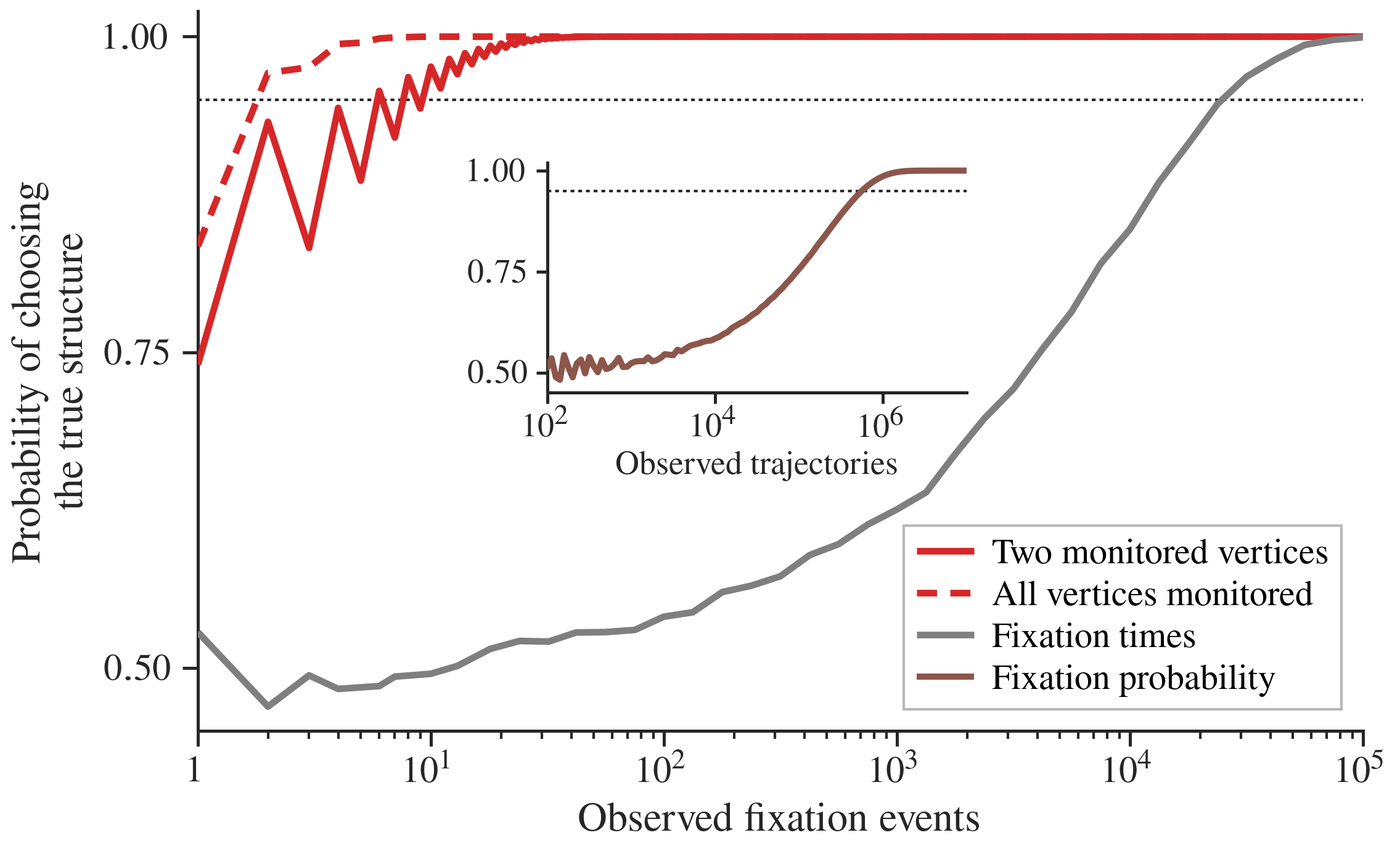

In [2]:
def extend(n, acc):
  return np.r_[n, 1e5], np.r_[acc, acc[-1]]


def powers(v, _):
  return r'$10^{%d}$' % round(np.log10(v)) if v >= 10 else r'$1$'


fig = plt.figure(figsize=(7.0, 6.95))
ax = fig.add_axes([0.52, 0.07, 0.45, 0.28])
ax.plot(*extend(d['n_two_sites'], d['acc_two_sites']), color=S.RED, label='Two monitored vertices', zorder=3)
ax.plot(*extend(d['n_all'], d['acc_all']), color=S.RED, ls=(0, (3, 2)), label='All vertices monitored', zorder=3)
ax.plot(d['n_time'], d['acc_time'], color=S.GRAY, label='Fixation times', zorder=3)
ax.axhline(0.95, color=S.INK, lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
ax.set_xscale('log')
ax.set_xlim(1, 1e5)
ax.set_ylim(0.45, 1.02)
ax.set_yticks([0.5, 0.75, 1])
ax.xaxis.set_major_formatter(mt.FuncFormatter(powers))
ax.set_xlabel('Observed fixation events')
ax.set_ylabel('Probability of choosing\nthe true structure')
axi = ax.inset_axes([0.30, 0.47, 0.36, 0.32])
axi.plot(d['n_fixation'], d['acc_fixation'], color=S.BROWN, lw=1.2, zorder=3)
axi.axhline(0.95, color=S.INK, lw=0.5, ls=(0, (1.5, 1.5)), zorder=1)
axi.set_xscale('log')
axi.set_xlim(1e2, 1e7)
axi.set_ylim(0.45, 1.02)
axi.set_yticks([0.5, 0.75, 1])
axi.set_xticks([1e2, 1e4, 1e6])
axi.xaxis.set_minor_locator(mt.NullLocator())
axi.xaxis.set_major_formatter(mt.FuncFormatter(powers))
axi.tick_params(labelsize=6, length=2.2, pad=1.5)
axi.set_xlabel('Observed trajectories', fontsize=6.5, labelpad=1.5)
hs, ls = ax.get_legend_handles_labels()
hs.append(Line2D([], [], color=S.BROWN, lw=1.2))
ls.append('Fixation probability')
S.legend(ax, handles=hs, labels=ls, loc='lower right', handlelength=1.6, borderpad=0.35, labelspacing=0.25)
S.save_panel(fig, 'g')